In [2]:
import matplotlib.pyplot as plt
import numpy as np
#matplotlib qt

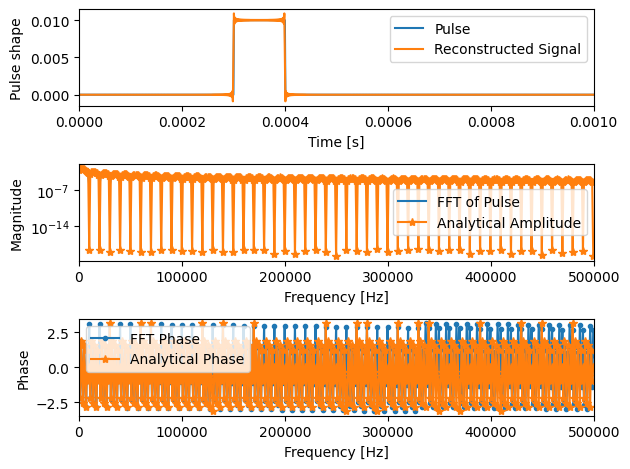

In [3]:
dt = 1e-6
frep = 1000
trep = 1/frep
tau=trep/10
ts = 3*tau

fig, ax = plt.subplots(3,1)

t=np.arange(0,trep,dt)
pul = np.zeros(len(t))
pul[(t >= ts) & (t < ts + tau)] = 1
pul=pul/np.sum(pul)

# Compute the FFT
spect = np.fft.fft(pul)/len(t)
freq = np.fft.fftfreq(len(t), d=dt)

# Keep only the positive frequencies
freqs = freq[freq >= 0]
spect = spect[freq >= 0]


inds = np.arange(0,len(spect))

A = np.max(pul)

an = np.zeros(len(inds))
bn = np.zeros(len(inds))

ampn = np.zeros(len(inds))
phn = np.zeros(len(inds))

sig = np.zeros(len(t))

an[0] = A*tau/trep
bn[0] = 0
sig += an[0]
for i in inds[1:]:
    
    scale = 2*A/np.pi/i
    an[i] = scale * np.cos(np.pi*i/trep*(tau+2*ts)) * np.sin(np.pi*i/trep*(tau))
    bn[i] = scale * np.sin(np.pi*i/trep*(tau+2*ts)) * np.sin(np.pi*i/trep*(tau))

    sig += an[i]*np.cos(2*np.pi*i*t/trep) + bn[i]*np.sin(2*np.pi*i*t/trep)

amp_comp = an+1j*bn
ampn = np.abs(amp_comp)
phn = -np.angle(amp_comp)



ax[0].plot(t,pul)
ax[0].plot(t,sig)

# ax[0].plot(t,pul2)
ax[0].set_xlabel('Time [s]')
ax[0].set_ylabel('Pulse shape')
ax[0].set_xlim([0, trep])

ax[1].plot(freqs,np.abs(spect))
# ax[1].plot(freqs,np.abs(spect2))
ax[1].plot(freqs,np.abs(ampn),marker = '*', linestyle = '-')
ax[1].set_xlabel('Frequency [Hz]')
ax[1].set_ylabel('Magnitude')
ax[1].set_xlim([0, 1/dt/2])
ax[1].set_yscale('log')

ax[2].plot(freqs,np.angle(spect),marker = '.', linestyle = '-')
# ax[2].plot(freqs,np.angle(spect2),marker = '.', linestyle = '-')
ax[2].plot(freqs,phn,marker = '*', linestyle = '-')
ax[2].set_xlabel('Frequency [Hz]')
ax[2].set_ylabel('Phase')
ax[2].set_xlim([0, 1/dt/2])

ax[0].legend(['Pulse', 'Reconstructed Signal']) 
ax[1].legend(['FFT of Pulse', 'Analytical Amplitude'])
ax[2].legend(['FFT Phase', 'Analytical Phase'])

plt.tight_layout()

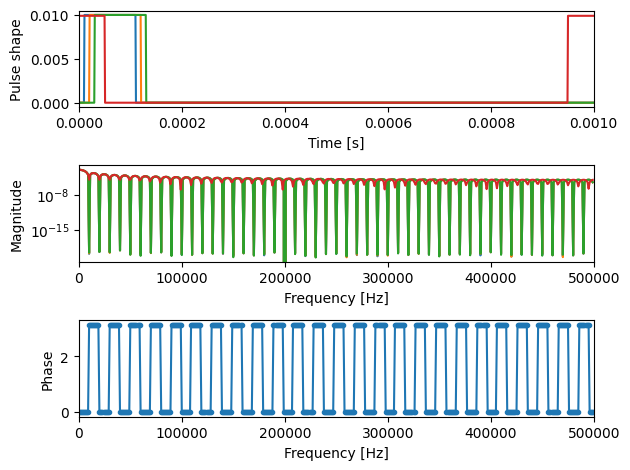

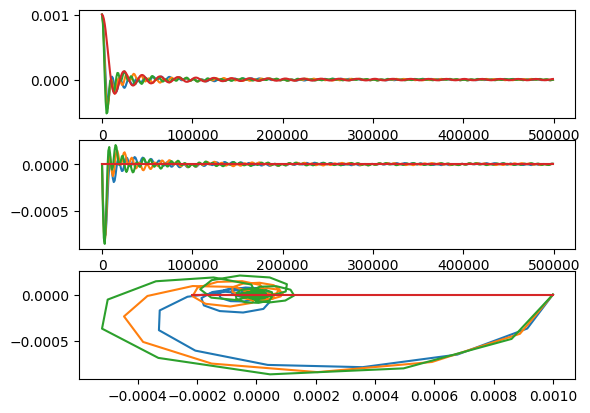

In [4]:
dt = 1e-6
frep = 1000
trep = 1/frep
tau=trep/10
ts1 = 0.1*tau
ts2 = 0.2*tau
ts3 = 0.3*tau


fig, ax = plt.subplots(3,1)

t=np.arange(0,trep-dt,dt)

pul_ref = np.zeros(len(t))
pul1 = np.zeros(len(t))
pul2 = np.zeros(len(t))
pul3 = np.zeros(len(t))

pul_ref[(t<= tau/2) | (t>=trep-tau/2)] = 1
pul1[(t >= ts1) & (t < ts1 + tau)] = 1
pul2[(t >= ts2) & (t < ts2 + tau)] = 1
pul3[(t >= ts3) & (t < ts3 + tau)] = 1

pul_ref=pul_ref/np.sum(pul_ref)
pul1=pul1/np.sum(pul1)
pul2=pul2/np.sum(pul2)
pul3=pul3/np.sum(pul3)


# Compute the FFT
spect_ref = np.fft.fft(pul_ref)/len(t)
spect1 = np.fft.fft(pul1)/len(t)
spect2 = np.fft.fft(pul2)/len(t)
spect3 = np.fft.fft(pul3)/len(t)
freq = np.fft.fftfreq(len(t), d=dt)

# Keep only the positive frequencies
freqs = freq[freq >= 0]
spect_ref = spect_ref[freq >= 0]
spect1 = spect1[freq >= 0]
spect2 = spect2[freq >= 0]
spect3 = spect3[freq >= 0]

ax[0].plot(t,pul1)
ax[0].plot(t,pul2)
ax[0].plot(t,pul3)
ax[0].plot(t,pul_ref)

# ax[0].plot(t,pul2)
ax[0].set_xlabel('Time [s]')
ax[0].set_ylabel('Pulse shape')
ax[0].set_xlim([0, trep])

ax[1].plot(freqs,np.abs(spect1))
ax[1].plot(freqs,np.abs(spect2))
ax[1].plot(freqs,np.abs(spect3))
ax[1].plot(freqs,np.abs(spect_ref))
ax[1].set_xlabel('Frequency [Hz]')
ax[1].set_ylabel('Magnitude')
ax[1].set_xlim([0, 1/dt/2])
ax[1].set_yscale('log')

# ax[2].plot(freqs,np.angle(spect1),marker = '.')
# ax[2].plot(freqs,np.angle(spect2),marker = '.')
# ax[2].plot(freqs,np.angle(spect3),marker = '.')
ax[2].plot(freqs,np.abs(np.angle(spect_ref)),marker = '.')
ax[2].set_xlabel('Frequency [Hz]')
ax[2].set_ylabel('Phase')
ax[2].set_xlim([0, 1/dt/2])


plt.tight_layout()

fig3, ax3 = plt.subplots(3,1)
ax3[0].plot(freqs,spect1.real)
ax3[0].plot(freqs,spect2.real)
ax3[0].plot(freqs,spect3.real)
ax3[0].plot(freqs,spect_ref.real)

ax3[1].plot(freqs,spect1.imag)
ax3[1].plot(freqs,spect2.imag)
ax3[1].plot(freqs,spect3.imag)
ax3[1].plot(freqs,spect_ref.imag)

ax3[2].plot(spect1.real,spect1.imag)
ax3[2].plot(spect2.real,spect2.imag)
ax3[2].plot(spect3.real,spect3.imag)
ax3[2].plot(spect_ref.real,spect_ref.imag)



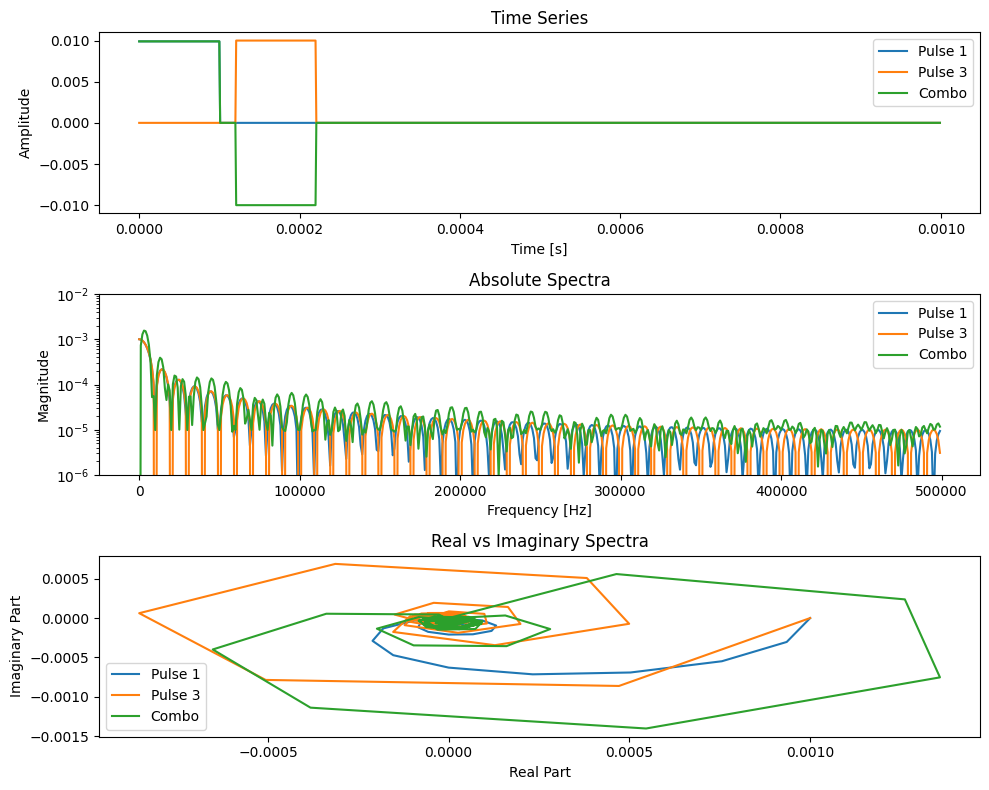

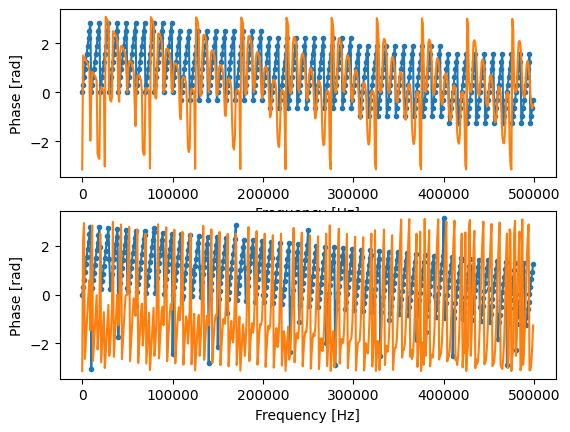

In [5]:
dt = 1e-6
frep = 1000
trep = 1/frep
tau=trep/10
ts1 = 0*tau
ts3 = 1.2*tau


t=np.arange(0,trep-dt,dt)

pul1 = np.zeros(len(t))
pul3 = np.zeros(len(t))

pul1[(t >= ts1) & (t < ts1 + tau)] = 1
pul3[(t >= ts3) & (t < ts3 + tau)] = 1

pul1=pul1/np.sum(pul1)
pul3=pul3/np.abs(np.sum(pul3))

combo = pul1 - pul3

# Compute the FFT
spect1 = np.fft.fft(pul1)/len(t)
spect3 = np.fft.fft(pul3)/len(t)
freq = np.fft.fftfreq(len(t), d=dt)

# Keep only the positive frequencies
freqs = freq[freq >= 0]
spect1 = spect1[freq >= 0]
spect3 = spect3[freq >= 0]


spect_combo = np.fft.fft(combo)/len(t)
spect_combo = spect_combo[freq >= 0]

phase0_combo = np.angle(spect_combo)
phase0_1 = np.angle(spect1)
phase0_3 = np.angle(spect3)

ph_inc_combo1 = 2*np.pi*freqs*(ts1+tau/2)
ph_inc_1 = 2*np.pi*freqs*(ts1+tau/2)
ph_inc_combo3 = 2*np.pi*freqs*(ts3+tau/2)
ph_inc_3 = 2*np.pi*freqs*(ts3+tau/2)

ph_inc_combo1 = 2*np.pi*freqs*(ts1+tau)
ph_inc_1 = 2*np.pi*freqs*(ts1+tau)
ph_inc_combo3 = 2*np.pi*freqs*(ts3+tau)
ph_inc_3 = 2*np.pi*freqs*(ts3+tau)

ph_combo1_shift = (phase0_combo+ph_inc_combo1 + np.pi) % (2 * np.pi) - np.pi
ph_1_shift = (phase0_1+ph_inc_1 + np.pi) % (2 * np.pi) - np.pi
ph_combo3_shift = (phase0_combo+ph_inc_combo3 + np.pi) % (2 * np.pi) - np.pi
ph_3_shift = (phase0_3+ph_inc_3 + np.pi) % (2 * np.pi) - np.pi

fig, ax = plt.subplots(3, 1, figsize=(10, 8))

# Plot time series
ax[0].plot(t, pul1, label='Pulse 1')
ax[0].plot(t, pul3, label='Pulse 3')
ax[0].plot(t, combo, label='Combo')
ax[0].set_xlabel('Time [s]')
ax[0].set_ylabel('Amplitude')
ax[0].legend()
ax[0].set_title('Time Series')

# Plot absolute spectra
ax[1].plot(freqs, np.abs(spect1), label='Pulse 1')
ax[1].plot(freqs, np.abs(spect3), label='Pulse 3')
ax[1].plot(freqs, np.abs(spect_combo), label='Combo')
ax[1].set_xlabel('Frequency [Hz]')
ax[1].set_ylabel('Magnitude')
ax[1].set_yscale('log')
ax[1].legend()
ax[1].set_title('Absolute Spectra')
ax[1].set_ylim([1e-6, 1e-2])
# Plot real vs imaginary spectra
ax[2].plot(spect1.real, spect1.imag, label='Pulse 1')
ax[2].plot(spect3.real, spect3.imag, label='Pulse 3')
ax[2].plot(spect_combo.real, spect_combo.imag, label='Combo')
ax[2].set_xlabel('Real Part')
ax[2].set_ylabel('Imaginary Part')
ax[2].legend()
ax[2].set_title('Real vs Imaginary Spectra')

plt.tight_layout()

fig2,ax2 = plt.subplots(2,1)

ax2[0].plot(freqs,ph_1_shift,marker = '.')
ax2[0].plot(freqs,ph_combo1_shift)
ax2[0].set_xlabel('Frequency [Hz]')
ax2[0].set_ylabel('Phase [rad]')

ax2[1].plot(freqs,ph_3_shift,marker = '.')
ax2[1].plot(freqs,ph_combo3_shift)
ax2[1].set_xlabel('Frequency [Hz]')
ax2[1].set_ylabel('Phase [rad]')

plt.show()


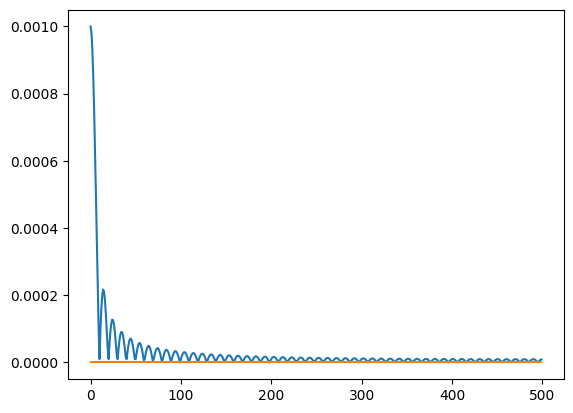

In [6]:
plt.plot(np.abs(spect_ref.real))
plt.plot(np.abs(spect_ref.imag))

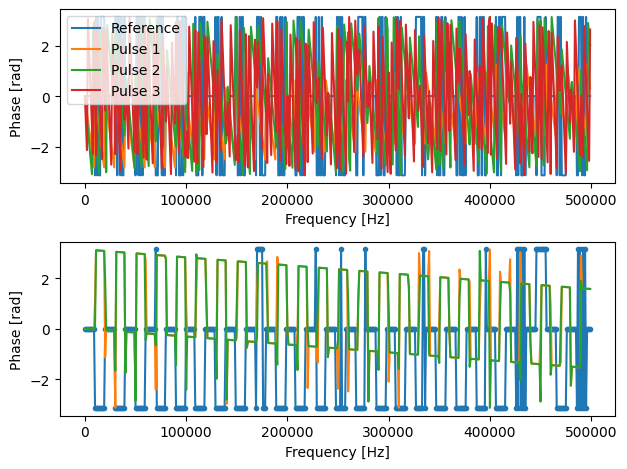

In [7]:
phase0_ref = np.angle(spect_ref)
phase0_1 = np.angle(spect1)
phase0_2 = np.angle(spect2)
phase0_3 = np.angle(spect3)

ph_inc_ref = 2*np.pi*freqs*tau/2
ph_inc_1 = 2*np.pi*freqs*(ts1+tau/2)
ph_inc_2 = 2*np.pi*freqs*(ts2+tau/2)
ph_inc_3 = 2*np.pi*freqs*(ts3+tau/2)

ph_ref_shift = (phase0_ref+ph_inc_ref + np.pi) % (2 * np.pi) - np.pi
ph_1_shift = (phase0_1+ph_inc_1 + np.pi) % (2 * np.pi) - np.pi
ph_2_shift = (phase0_2+ph_inc_2 + np.pi) % (2 * np.pi) - np.pi
ph_3_shift = (phase0_3+ph_inc_3 + np.pi) % (2 * np.pi) - np.pi


fig2,ax2 = plt.subplots(2,1)


ax2[0].plot(freqs, phase0_ref)
ax2[0].plot(freqs, phase0_1)
ax2[0].plot(freqs, phase0_2)
ax2[0].plot(freqs, phase0_3)
ax2[0].set_xlabel('Frequency [Hz]')
ax2[0].set_ylabel('Phase [rad]')
ax2[0].legend(['Reference', 'Pulse 1', 'Pulse 2', 'Pulse 3'])



# ax2[1].plot(freqs,ph_ref_shift)
ax2[1].plot(freqs,ph_1_shift,marker = '.')
ax2[1].plot(freqs,ph_2_shift)
ax2[1].plot(freqs,ph_3_shift)
ax2[1].set_xlabel('Frequency [Hz]')
ax2[1].set_ylabel('Phase [rad]')


    
plt.tight_layout()






In [8]:
np.diff(ph_1_shift)[0:10]


array([ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00, -4.44089210e-16,
        4.44089210e-16, -3.14159265e+00])

In [9]:
freqs[0:2]

array([   0., 1000.])